In [6]:
import sys
sys.path.append('../')

import numpy as np
import pickle

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

### Ablation: Weighted CC with vs. without Augmentation
(GMM2D5v1kNN)

In [7]:
methods = ['WeightedCC', 'WeightedCC_NA_OH']
labels = {'WeightedCC': 'Weighted CC', 'WeightedCC_NA_OH': 'Weighted CC (No Augmentation)'}
fmts = {'WeightedCC': 'bo-', 'WeightedCC_NA_OH': 'C1o--'}

### **Fixed Sample Size**

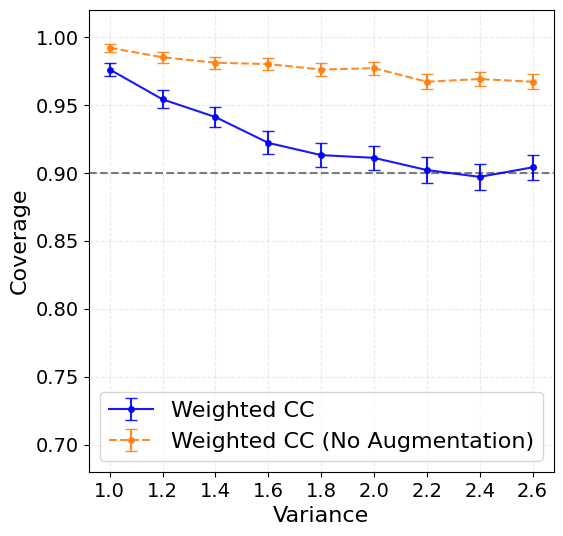

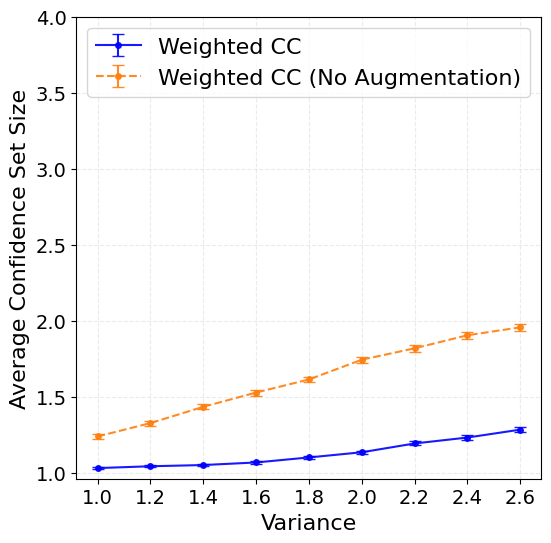

In [8]:
n = 1200
B = 1000
var_range = np.linspace(1, 2.6, 9)

with open(f'Results/ablation_GMM2D5v1kNN.pkl', 'rb') as f:
    results = pickle.load(f)

coverages = {}
sizes = {}

for method in methods:
    cov, size = np.zeros((len(var_range), B)), np.zeros((len(var_range), B))
    for var_idx in range(len(var_range)):
        for b in range(B):
            res = results[var_idx*B + b]
            cov[var_idx, b], size[var_idx, b] = res[method]

    # Mean and standard error over B experiments
    cov_mean, cov_se = np.mean(cov, axis=1), np.std(cov, axis=1) / np.sqrt(B)
    size_mean, size_se = np.mean(size, axis=1), np.std(size, axis=1) / np.sqrt(B)

    # Store results for plotting
    coverages[method] = (cov_mean, cov_se)
    sizes[method] = (size_mean, size_se)


# Errorbars with connected lines
plt.figure(figsize=(6,6))
for method in methods:
    plt.errorbar(var_range, coverages[method][0], yerr=coverages[method][1], fmt=fmts[method], capsize=4, markersize=4, alpha=0.9, label=labels[method])
plt.axhline(y=0.9, color='k', linestyle='--', alpha=0.5)
plt.xlabel('Variance', fontsize=16)
plt.xticks(ticks=var_range, labels=[f"{v:.1f}" for v in var_range], fontsize=14)
plt.ylabel('Coverage', fontsize=16)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.grid(True, linestyle="--", alpha=0.25)
plt.ylim((0.68, 1.02))
plt.show()


plt.figure(figsize=(6,6))
for method in methods:
    plt.errorbar(var_range, sizes[method][0], yerr=sizes[method][1], fmt=fmts[method], capsize=4, markersize=4, alpha=0.9, label=labels[method])
plt.xlabel('Variance', fontsize=16)
plt.xticks(ticks=var_range, labels=[f"{v:.1f}" for v in var_range], fontsize=14)
plt.ylabel('Average Confidence Set Size', fontsize=16)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.grid(True, linestyle="--", alpha=0.25)
plt.ylim((0.96, 4.0))
plt.show()

### **Asymptotic: Increasing Sample Size**

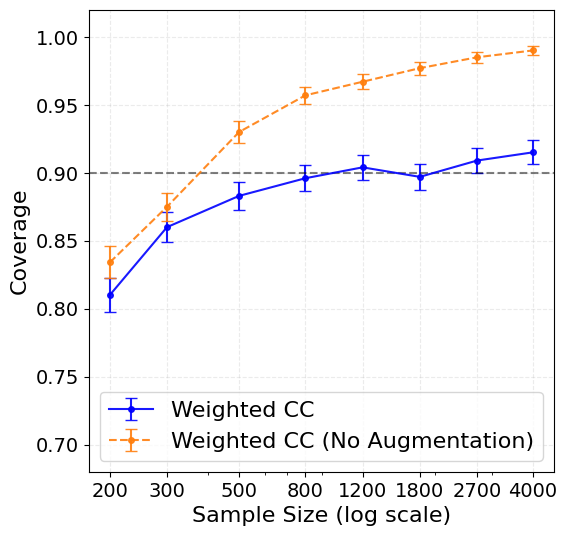

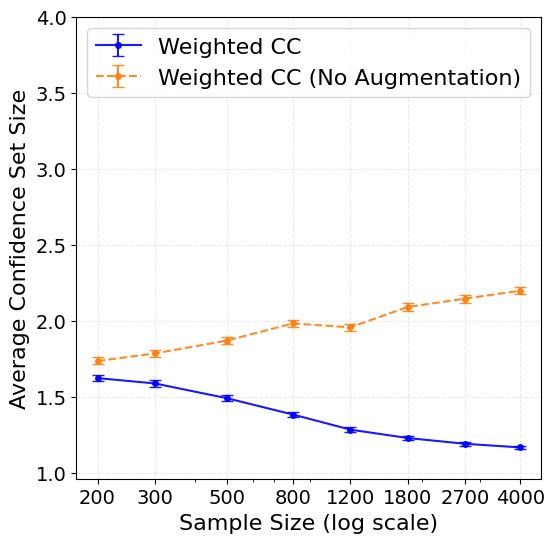

In [9]:
var = 2.6
B = 1000
n_range = [200, 300, 500, 800, 1200, 1800, 2700, 4000]

with open(f'Results/ablation_GMM2D5v1kNN_asymp.pkl', 'rb') as f:
    results = pickle.load(f)

asymp_coverages = {}
asymp_sizes = {}

for method in methods:
    cov, size = np.zeros((len(n_range), B)), np.zeros((len(n_range), B))
    for n_idx in range(len(n_range)):
        for b in range(B):
            res = results[n_idx*B + b]
            cov[n_idx, b], size[n_idx, b] = res[method]

    # Mean and standard error over B experiments
    cov_mean, cov_se = np.mean(cov, axis=1), np.std(cov, axis=1) / np.sqrt(B)
    size_mean, size_se = np.mean(size, axis=1), np.std(size, axis=1) / np.sqrt(B)

    # Store results for plotting
    asymp_coverages[method] = (cov_mean, cov_se)
    asymp_sizes[method] = (size_mean, size_se)


# Errorbars with connected lines (x-axis = sample size in log scale)
plt.figure(figsize=(6,6))
for method in methods:
    plt.errorbar(n_range, asymp_coverages[method][0], yerr=asymp_coverages[method][1], fmt=fmts[method], capsize=4, markersize=4, alpha=0.9, label=labels[method])
plt.axhline(y=0.9, color='k', linestyle='--', alpha=0.5)
plt.xlabel('Sample Size (log scale)', fontsize=16)
plt.xscale('log')
plt.xticks(ticks=n_range, labels=[str(n) for n in n_range], fontsize=14)
plt.ylabel('Coverage', fontsize=16)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.grid(True, linestyle="--", alpha=0.25)
plt.ylim((0.68, 1.02))
plt.show()


plt.figure(figsize=(6,6))
for method in methods:
    plt.errorbar(n_range, asymp_sizes[method][0], yerr=asymp_sizes[method][1], fmt=fmts[method], capsize=4, markersize=4, alpha=0.9, label=labels[method])
plt.xlabel('Sample Size (log scale)', fontsize=16)
plt.xscale('log')
plt.xticks(ticks=n_range, labels=[str(n) for n in n_range], fontsize=14)
plt.ylabel('Average Confidence Set Size', fontsize=16)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.grid(True, linestyle="--", alpha=0.25)
plt.ylim((0.96, 4.0))
plt.show()

### Combined Figures

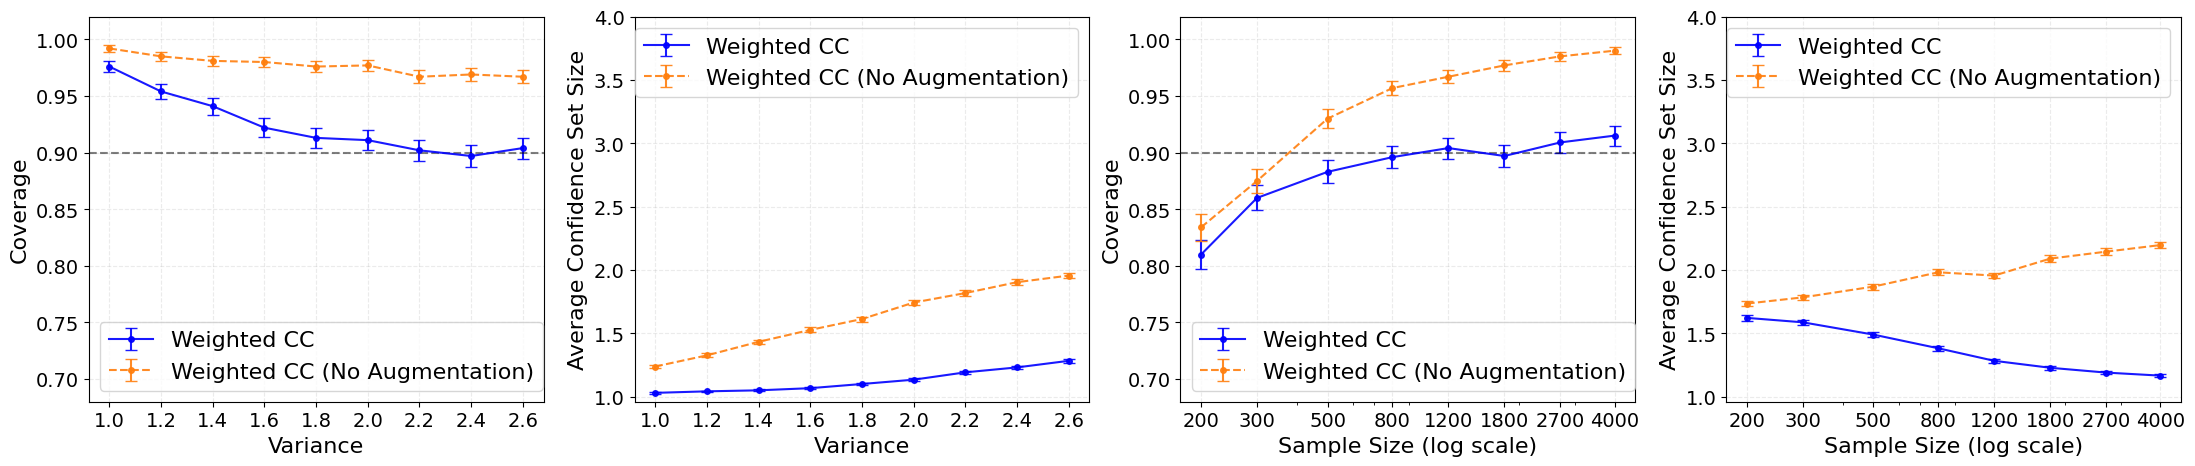

In [10]:
fig = plt.figure(figsize=(27, 5))
gs = GridSpec(nrows=1, ncols=4, figure=fig, wspace=0.2, hspace=0.2)

# Coverage (fixed sample size)
ax1 = fig.add_subplot(gs[0, 0])
for method in methods:
    ax1.errorbar(var_range, coverages[method][0], yerr=coverages[method][1], fmt=fmts[method], capsize=4, markersize=4, alpha=0.9, label=labels[method])
ax1.axhline(y=0.9, color='k', linestyle='--', alpha=0.5)
ax1.set_xlabel('Variance', fontsize=16)
ax1.set_xticks(var_range)
ax1.set_xticklabels(labels=[f"{v:.1f}" for v in var_range], fontsize=14)
ax1.set_ylabel('Coverage', fontsize=16)
ax1.tick_params(axis='y', labelsize=14)
ax1.legend(fontsize=16)
ax1.grid(True, linestyle="--", alpha=0.25)
ax1.set_ylim((0.68, 1.02))

# Size (fixed sample size)
ax2 = fig.add_subplot(gs[0, 1])
for method in methods:
    ax2.errorbar(var_range, sizes[method][0], yerr=sizes[method][1], fmt=fmts[method], capsize=4, markersize=4, alpha=0.9, label=labels[method])
ax2.set_xlabel('Variance', fontsize=16)
ax2.set_xticks(var_range)
ax2.set_xticklabels(labels=[f"{v:.1f}" for v in var_range], fontsize=14)
ax2.set_ylabel('Average Confidence Set Size', fontsize=16)
ax2.tick_params(axis='y', labelsize=14)
ax2.legend(fontsize=16)
ax2.grid(True, linestyle="--", alpha=0.25)
ax2.set_ylim((0.96, 4.0))

# Asymptotic coverage
ax3 = fig.add_subplot(gs[0, 2])
for method in methods:
    ax3.errorbar(n_range, asymp_coverages[method][0], yerr=asymp_coverages[method][1], fmt=fmts[method], capsize=4, markersize=4, alpha=0.9, label=labels[method])
ax3.axhline(y=0.9, color='k', linestyle='--', alpha=0.5)
ax3.set_xlabel('Sample Size (log scale)', fontsize=16)
ax3.set_xscale('log')
ax3.set_xticks(n_range)
ax3.set_xticklabels([str(n) for n in n_range], fontsize=14)
ax3.set_ylabel('Coverage', fontsize=16)
ax3.tick_params(axis='y', labelsize=14)
ax3.legend(fontsize=16)
ax3.grid(True, linestyle="--", alpha=0.25)
ax3.set_ylim((0.68, 1.02))

# Asymptotic size
ax4 = fig.add_subplot(gs[0, 3])
for method in methods:
    ax4.errorbar(n_range, asymp_sizes[method][0], yerr=asymp_sizes[method][1], fmt=fmts[method], capsize=4, markersize=4, alpha=0.9, label=labels[method])
ax4.set_xlabel('Sample Size (log scale)', fontsize=16)
ax4.set_xscale('log')
ax4.set_xticks(n_range)
ax4.set_xticklabels([str(n) for n in n_range], fontsize=14)
ax4.set_ylabel('Average Confidence Set Size', fontsize=16)
ax4.tick_params(axis='y', labelsize=14)
ax4.legend(fontsize=16)
ax4.grid(True, linestyle="--", alpha=0.25)
ax4.set_ylim((0.96, 4.0))

plt.savefig('Figures/ablation_GMM2D5v1kNN.pdf', bbox_inches='tight')
plt.show()